**Set environment**

In [1]:
suppressMessages(suppressWarnings(source("../run_config_project_sing.R")))
suppressMessages(suppressWarnings(library(mclust)))
show_env()

You are working on        Singularity: singularity_proj_encode_fcc 
BASE DIRECTORY (FD_BASE): /data/reddylab/Kuei 
REPO DIRECTORY (FD_REPO): /data/reddylab/Kuei/repo 
WORK DIRECTORY (FD_WORK): /data/reddylab/Kuei/work 
DATA DIRECTORY (FD_DATA): /data/reddylab/Kuei/data 

You are working with      ENCODE FCC 
PATH OF PROJECT (FD_PRJ): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC 
PROJECT RESULTS (FD_RES): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results 
PROJECT SCRIPTS (FD_EXE): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/scripts 
PROJECT DATA    (FD_DAT): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/data 
PROJECT NOTE    (FD_NBK): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/notebooks 
PROJECT DOCS    (FD_DOC): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/docs 
PROJECT LOG     (FD_LOG): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/log 
PROJECT REF     (FD_REF): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/references 



**Set global variable**

In [2]:
### get annotated region folder
vec = c(
    "fcc_astarr_macs_input_overlap",
    "fcc_astarr_macs_input_union"
)
names(vec) = vec

### assign and show
vec_txt_folder = vec
for(txt in vec){cat(txt, "\n")}

fcc_astarr_macs_input_overlap 
fcc_astarr_macs_input_union 


## Import data

In [3]:
### set file directory
txt_fdiry = file.path(
    FD_RES, 
    "analysis_umap_cluster_by_coverage", 
    "fcc_astarr_macs_input_overlap",
    "fcc_starrmpracrispri_vote2",
    "summary"
)
txt_fname = "region.phenograph.coverage.encode_chipseq_full_log2p.cluster.tsv"
txt_fpath = file.path(txt_fdiry, txt_fname)

### read table
dat = read_tsv(txt_fpath, show_col_types = FALSE)

### assign and show
dat_region_phenograph_cluster = dat
print(any(is.na(dat)))
print(dim(dat))
head(dat)

[1] FALSE
[1] 33953     9


Region,Cluster_k30,Cluster_k40,Cluster_k50,Cluster_k60,Cluster_k70,Cluster_k80,Cluster_k90,Cluster_k100
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
chr1:605104-605675,8,10,8,7,7,7,7,7
chr1:778233-779389,6,6,0,0,0,0,0,0
chr1:818708-819335,13,4,8,7,7,5,5,5
chr1:826796-828040,0,6,0,0,0,0,0,0
chr1:842516-843431,1,8,1,1,1,1,1,1
chr1:903783-905204,0,7,3,4,6,6,4,4


In [4]:
### set file directory
txt_fdiry = file.path(
    FD_RES, 
    "analysis_umap_cluster_by_coverage", 
    "fcc_astarr_macs_input_overlap",
    "fcc_starrmpracrispri_vote2",
    "summary"
)
txt_fname = "region.phenograph.coverage.encode_chipseq_full_log2p.summary.tsv"
txt_fpath = file.path(txt_fdiry, txt_fname)

### read table
dat = read_tsv(txt_fpath, show_col_types = FALSE)

### assign and show
dat_region_phenograph_summary = dat
print(any(is.na(dat)))
print(dim(dat))
head(dat)

[1] FALSE
[1]  8 11


k,Q,n_clusters,smallest_cluster,largest_cluster,mean_degree,min_degree,max_degree,mean_edge_weight,min_edge_weight,max_edge_weight
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
30,0.785819,22,57,6091,53.19471,19,1182,0.08161182,0.008474576,0.9354839
40,0.777939,21,55,4525,71.20950,30,1412,0.08617898,0.006329114,0.9047619
50,0.770219,19,57,6792,88.89070,41,1604,0.09023093,0.005050505,0.8867925
60,0.765683,18,88,7089,106.39955,52,1767,0.09376667,0.004201681,0.9047619
70,0.760761,18,52,7210,123.75572,61,1932,0.09691867,0.003597122,0.8918919
80,0.755270,16,55,6885,141.04179,74,2067,0.09975333,0.003144654,0.9512195


## Set plotting style

In [5]:
### set text size
THEME_TEXT = theme(
    title      = element_text(size = 16),
    axis.title = element_text(size = 16),
    axis.text  = element_text(size = 16),
    #legend.title = element_text(size = 16),
    legend.title = element_blank(),
    legend.text  = element_text(size = 16),
    strip.text   = element_text(size = 16)
)

## Similarity of different clustering/partitions (k = 30-100)

In [6]:
### init
ks  = seq(30, 100, by = 10)
ks  = paste0("Cluster_k", ks)
n   = length(ks)

### calculate adjusted Rand index across clustering
mat = matrix(NA, n, n, dimnames = list(ks, ks))
for (i in 1:n) {
    for (j in 1:n) {
        mat[i,j] <- adjustedRandIndex(
            dat_region_phenograph_cluster[[ks[i]]],
            dat_region_phenograph_cluster[[ks[j]]]
        )
    }
}

### assign and show
mat_cluster_ari = mat
print(dim(mat))
fun_display_table(mat)

[1] 8 8


,Cluster_k30,Cluster_k40,Cluster_k50,Cluster_k60,Cluster_k70,Cluster_k80,Cluster_k90,Cluster_k100
Cluster_k30,1.0000000,0.6681370,0.5482042,0.5330836,0.5340562,0.5865529,0.5125589,0.5150496
Cluster_k40,0.6681370,1.0000000,0.5969078,0.5497077,0.5418759,0.6156649,0.5363262,0.5257199
Cluster_k50,0.5482042,0.5969078,1.0000000,0.8026590,0.7581788,0.7014684,0.7840786,0.7485627
Cluster_k60,0.5330836,0.5497077,0.8026590,1.0000000,0.8513623,0.7135115,0.8344592,0.8681315
Cluster_k70,0.5340562,0.5418759,0.7581788,0.8513623,1.0000000,0.7645308,0.8781221,0.8575245
Cluster_k80,0.5865529,0.6156649,0.7014684,0.7135115,0.7645308,1.0000000,0.7763515,0.7366282
Cluster_k90,0.5125589,0.5363262,0.7840786,0.8344592,0.8781221,0.7763515,1.0000000,0.8764409
Cluster_k100,0.5150496,0.5257199,0.7485627,0.8681315,0.8575245,0.7366282,0.8764409,1.0000000


**Arrange results**

In [7]:
### convert wide matrix to long table
mat = mat_cluster_ari
dat = reshape2::melt(mat)
colnames(dat) = c("Var1", "Var2", "Value")

### update column for plot
dat = dat %>% 
    dplyr::mutate(Label1 = gsub("Cluster_k", "k=", Var1)) %>%
    dplyr::mutate(Label2 = gsub("Cluster_k", "k=", Var2)) %>%
    dplyr::mutate(Label1 = factor(Label1, levels = paste0("k=", seq(30, 100, by=10)))) %>%
    dplyr::mutate(Label2 = factor(Label2, levels = paste0("k=", seq(30, 100, by=10))))

### assign and show
dat_cluster_ari = dat
print(dim(dat))
fun_display_table(head(dat, 3))

[1] 64  5


Var1,Var2,Value,Label1,Label2
Cluster_k30,Cluster_k30,1.0000000,k=30,k=30
Cluster_k40,Cluster_k30,0.6681370,k=40,k=30
Cluster_k50,Cluster_k30,0.5482042,k=50,k=30


**Generate plot**

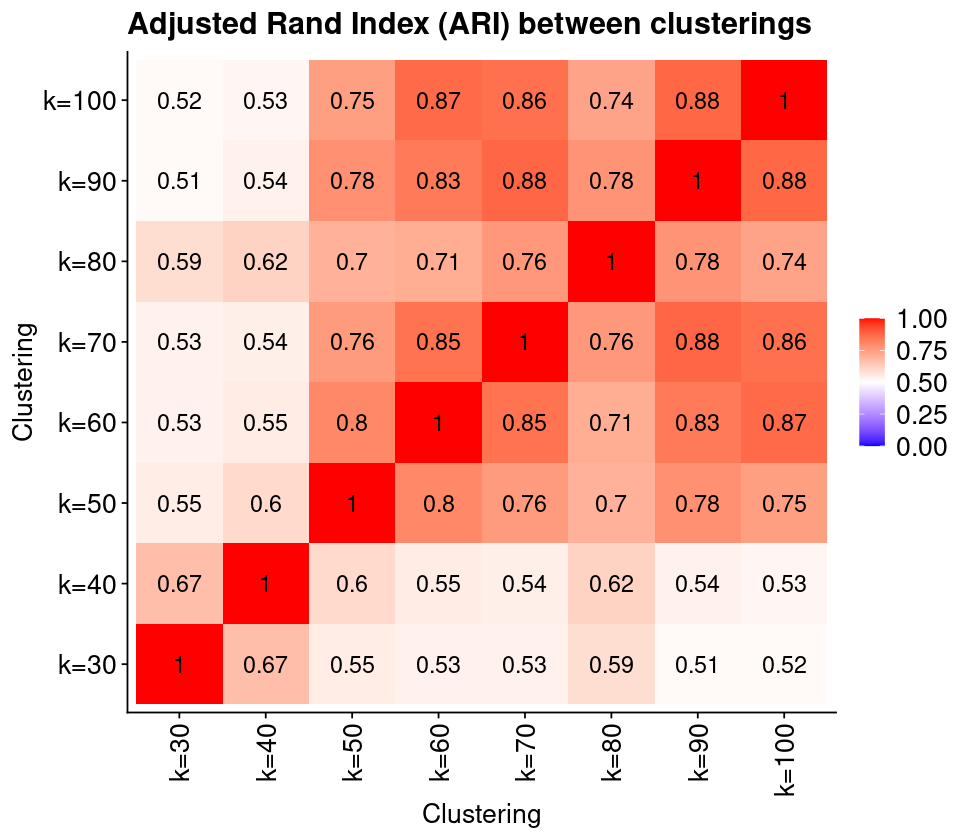

In [8]:
### init
dat = dat_cluster_ari
theme_text = THEME_TEXT

### plot heatmap
gpt = ggplot(dat, aes(Label1, Label2, fill = Value)) +
    geom_tile() +
    geom_text(aes(label = round(Value, 2)), color = "black") +
    scale_fill_gradient2(
        low = "blue", high = "red", mid = "white",
        midpoint = 0.5, limit = c(0,1)) +
    theme_cowplot() +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) +
    labs(
        title = "Adjusted Rand Index (ARI) between clusterings",
        x = "Clustering", 
        y = "Clustering", 
        fill = "ARI"
    ) +
    theme_text

### asssign and show
gpt_export_heatmap_ari_across_k = gpt
options(repr.plot.height=7, repr.plot.width=8)
print(gpt)

## Number of cluster and Q score over k

In [9]:
dat = dat_region_phenograph_summary 
fun_display_table(head(dat, 3))

k,Q,n_clusters,smallest_cluster,largest_cluster,mean_degree,min_degree,max_degree,mean_edge_weight,min_edge_weight,max_edge_weight
30,0.785819,22,57,6091,53.19471,19,1182,0.0816118,0.0084746,0.9354839
40,0.777939,21,55,4525,71.20950,30,1412,0.0861790,0.0063291,0.9047619
50,0.770219,19,57,6792,88.89070,41,1604,0.0902309,0.0050505,0.8867925


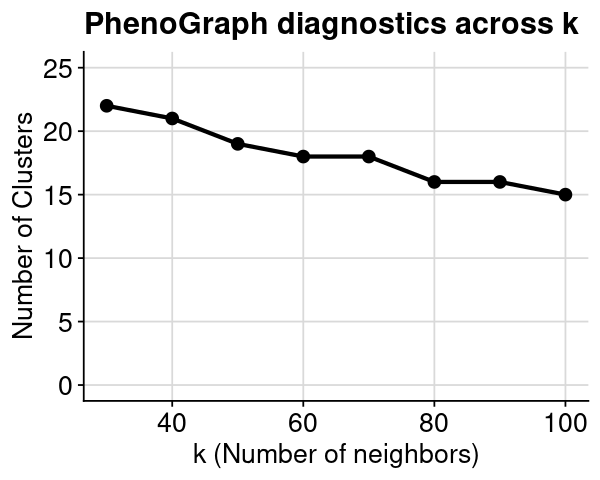

In [10]:
### init
dat = dat_region_phenograph_summary 

### generate plot
gpt = ggplot(dat, aes(x = k, y = n_clusters)) +
    geom_line(linewidth = 1.2) +
    geom_point(size = 3) +
    labs(
        title = "PhenoGraph diagnostics across k",
        x = "k (Number of neighbors)",
        y = "Number of Clusters") +
    theme_cowplot() +
    background_grid() +
    ylim(0, 25) +
    theme_text

### assign and show
gpt_export_numclust_across_k = gpt
options(repr.plot.height=4, repr.plot.width=5)
print(gpt)

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


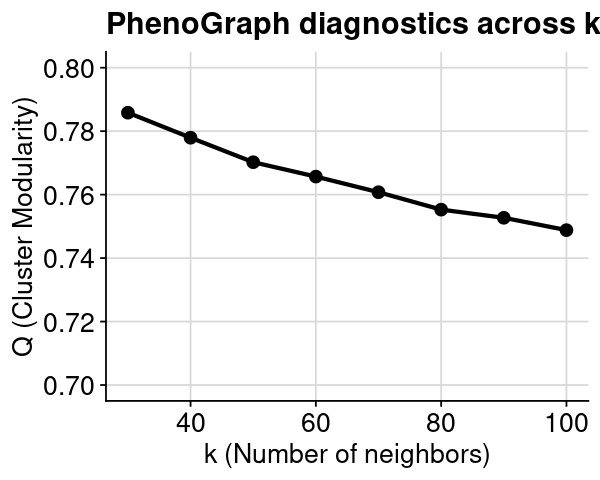

In [11]:
dat = dat_region_phenograph_summary 

gpt = ggplot(dat, aes(x = k, y = Q)) +
    geom_line(size = 1.2) +
    geom_point(size = 3) +
    labs(
        title = "PhenoGraph diagnostics across k",
        x = "k (Number of neighbors)",
        y = "Q (Cluster Modularity)") +
    theme_cowplot() +
    background_grid() +
    scale_y_continuous(
        breaks = seq(0.7, 0.8, by = 0.02),
        limits = c(0.7, 0.8)
  ) +
    theme_text

### assign and show
gpt_export_qscore_across_k = gpt
options(repr.plot.height=4, repr.plot.width=5)
print(gpt)

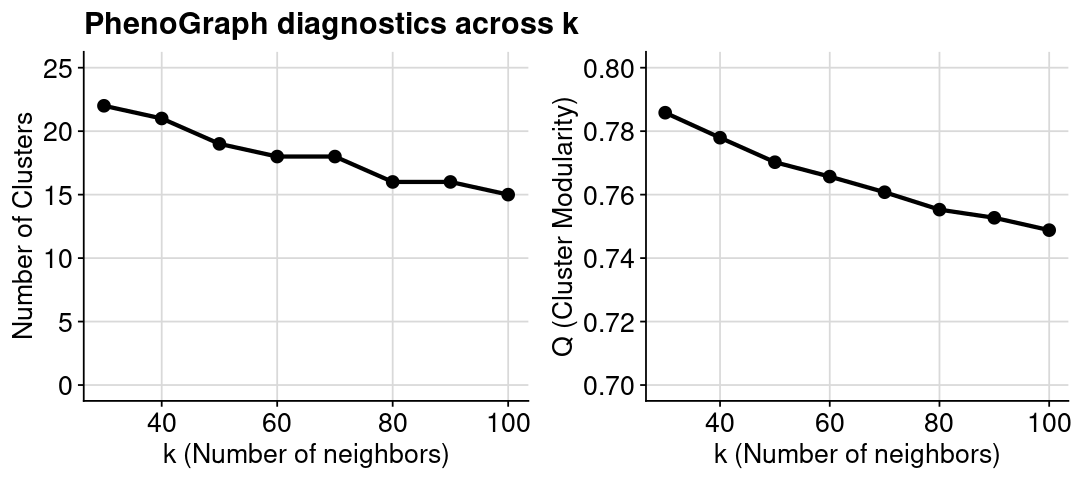

In [12]:
plt = plot_grid(
    gpt_export_numclust_across_k,
    gpt_export_qscore_across_k + labs(title = ""),
    nrow = 1
)

### assign and show
plt_export_metric_across_k = plt
options(repr.plot.height=4, repr.plot.width=9)
print(plt)

## Export results

**Export table**

In [13]:
### set file directory
txt_fdiry = file.path(
    FD_RES, 
    "analysis_umap_cluster_by_coverage", 
    "fcc_astarr_macs_input_overlap",
    "fcc_starrmpracrispri_vote2",
    "summary"
)
txt_fname = "region.phenograph.coverage.encode_chipseq_full_log2p.adjusted_rand_index.tsv"
txt_fpath = file.path(txt_fdiry, txt_fname)

### write table
dat = dat_cluster_ari
write_tsv(dat, txt_fpath)

**Export figure**

In [14]:
plt_export = gpt_export_heatmap_ari_across_k
txt_export = "fig.region.atac_overlap.fcc_starrmpracrispr_vote2.phenograph.heatmap.ari_across_k"
num_height = 7
num_width  = 8

txt_fdiry = "./"
txt_fname = paste(txt_export, "png", sep = ".")
txt_fpath = file.path(txt_fdiry, txt_fname)
ggsave(txt_fpath, plt_export, height = num_height, width = num_width, units = "in")

txt_fdiry = "./"
txt_fname = paste(txt_export, "svg", sep = ".")
txt_fpath = file.path(txt_fdiry, txt_fname)
ggsave(txt_fpath, plt_export, height = num_height, width = num_width, units = "in")

In [15]:
plt_export = plt_export_metric_across_k
txt_export = "fig.region.atac_overlap.fcc_starrmpracrispr_vote2.phenograph.lineplot.metric_across_k"
num_height = 4
num_width  = 9

txt_fdiry = "./"
txt_fname = paste(txt_export, "png", sep = ".")
txt_fpath = file.path(txt_fdiry, txt_fname)
ggsave(txt_fpath, plt_export, height = num_height, width = num_width, units = "in")

txt_fdiry = "./"
txt_fname = paste(txt_export, "svg", sep = ".")
txt_fpath = file.path(txt_fdiry, txt_fname)
ggsave(txt_fpath, plt_export, height = num_height, width = num_width, units = "in")